In [2]:
!pip install -U google-genai python-dotenv

     ---------------------------------------- 0.0/56.3 kB ? eta -:--:--
     ------- -------------------------------- 10.2/56.3 kB ? eta -:--:--
     ------- -------------------------------- 10.2/56.3 kB ? eta -:--:--
     ------------- ------------------------ 20.5/56.3 kB 131.3 kB/s eta 0:00:01
     -------------------- ----------------- 30.7/56.3 kB 145.2 kB/s eta 0:00:01
     --------------------------- ---------- 41.0/56.3 kB 178.6 kB/s eta 0:00:01
     ---------------------------------- --- 51.2/56.3 kB 187.0 kB/s eta 0:00:01
     -------------------------------------- 56.3/56.3 kB 184.3 kB/s eta 0:00:00
   ---------------------------------------- 0.0/1.2 MB ? eta -:--:--
   - -------------------------------------- 0.0/1.2 MB 2.0 MB/s eta 0:00:01
   -- ------------------------------------- 0.1/1.2 MB 825.8 kB/s eta 0:00:02
   ----- ---------------------------------- 0.2/1.2 MB 1.3 MB/s eta 0:00:01
   ------- -------------------------------- 0.2/1.2 MB 1.2 MB/s eta 0:00:01
   ----

In [4]:
from google import genai
import getpass

print("Google GenAI imported successfully!")

Google GenAI imported successfully!


In [6]:
api_key = getpass.getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

print("Gemini client created successfully!")

Enter your Gemini API Key:  ········


Gemini client created successfully!


In [10]:
import json
import pandas as pd

# Load final chunks
with open("midocean_chunks_final.json", "r", encoding="utf-8") as f:
    chunks = json.load(f)

print("Number of chunks:", len(chunks))

# Load RQ1 + RQ2 summary
rq1_rq2_results = pd.read_csv("RQ1_RQ2_final_results.csv")

print("\nRQ1/RQ2 results:")
display(rq1_rq2_results)

Number of chunks: 101

RQ1/RQ2 results:


,Method,Recall@5,Recall@10,MRR,NDCG@10
0,BM25 (Sparse),0.80,0.84,0.6455,0.6938
1,BGE-M3 (Dense),0.94,0.96,0.8258,0.8599
2,Hybrid (BM25 + BGE-M3),0.94,0.98,0.7758,0.8257
3,Hybrid + Reranking,0.98,0.98,0.8800,0.9057


In [20]:
import json

# Load the 50 evaluation questions
with open("evaluation_queries_final.json", "r", encoding="utf-8") as f:
    evaluation_queries = json.load(f)

# Load all chunks
with open("midocean_chunks_final.json", "r", encoding="utf-8") as f:
    chunks = json.load(f)

print("Number of questions:", len(evaluation_queries))
print("Number of chunks:", len(chunks))

Number of questions: 50
Number of chunks: 101


In [48]:
import json
import time

generation_results = []

for i, item in enumerate(reranked_all):

    question = item["query"]

    context = "\n\n".join(
        [
            f"Chunk ID: {chunk['chunk_id']}\n{chunk['text']}"
            for chunk in item["results"]
        ]
    )

    prompt = f"""
Answer the question using only the retrieved context.

Question:
{question}

Retrieved Context:
{context}

Instructions:
- Answer in Arabic.
- Do not use external knowledge.
- Do not invent information.
- If the answer is not supported by the retrieved context, say:
"لا توجد معلومات كافية في المصادر المسترجعة."
"""

    try:
        interaction = client.interactions.create(
            model="gemini-3-flash-preview",
            input=prompt
        )

        answer = interaction.output_text

    except Exception as e:
        answer = f"ERROR: {str(e)}"

    generation_results.append({
        "query_id": item["query_id"],
        "query": question,
        "retrieved_chunk_ids": [
            chunk["chunk_id"] for chunk in item["results"]
        ],
        "answer": answer
    })

    print(f"Completed {i+1}/50 - {item['query_id']}")

    time.sleep(1)

print("\nGeneration completed!")

Completed 1/50 - Q01
Completed 2/50 - Q02
Completed 3/50 - Q03
Completed 4/50 - Q04
Completed 5/50 - Q05
Completed 6/50 - Q06
Completed 7/50 - Q07
Completed 8/50 - Q08
Completed 9/50 - Q09
Completed 10/50 - Q10
Completed 11/50 - Q11
Completed 12/50 - Q12
Completed 13/50 - Q13
Completed 14/50 - Q14
Completed 15/50 - Q15
Completed 16/50 - Q16
Completed 17/50 - Q17
Completed 18/50 - Q18
Completed 19/50 - Q19
Completed 20/50 - Q20
Completed 21/50 - Q21
Completed 22/50 - Q22
Completed 23/50 - Q23
Completed 24/50 - Q24
Completed 25/50 - Q25
Completed 26/50 - Q26
Completed 27/50 - Q27
Completed 28/50 - Q28
Completed 29/50 - Q29
Completed 30/50 - Q30
Completed 31/50 - Q31
Completed 32/50 - Q32
Completed 33/50 - Q33
Completed 34/50 - Q34
Completed 35/50 - Q35
Completed 36/50 - Q36
Completed 37/50 - Q37
Completed 38/50 - Q38
Completed 39/50 - Q39
Completed 40/50 - Q40
Completed 41/50 - Q41
Completed 42/50 - Q42
Completed 43/50 - Q43
Completed 44/50 - Q44
Completed 45/50 - Q45
Completed 46/50 - Q

In [50]:
import json

with open("generation_results.json", "w", encoding="utf-8") as f:
    json.dump(generation_results, f, ensure_ascii=False, indent=2)

print("Saved successfully!")
print("Number of generated answers:", len(generation_results))

Saved successfully!
Number of generated answers: 50


In [52]:
for item in generation_results[:5]:
    print("=" * 100)
    print("Query ID:", item["query_id"])
    print("Question:", item["query"])
    
    print("\nRetrieved Chunks:")
    print(", ".join(item["retrieved_chunk_ids"]))
    
    print("\nGenerated Answer:")
    print(item["answer"])
    
    print("\n")

Query ID: Q01
Question: ما هي البرامج المتاحة في مرحلة الماجستير؟

Retrieved Chunks:
DOC_001_CHUNK_0005, DOC_003_CHUNK_0061, DOC_003_CHUNK_0056, DOC_001_CHUNK_0006, DOC_001_CHUNK_0003, DOC_001_CHUNK_0016, DOC_003_CHUNK_0060, DOC_003_CHUNK_0054, DOC_001_CHUNK_0018, DOC_001_CHUNK_0004

Generated Answer:
بناءً على السياق المسترجع، البرامج المتاحة في مرحلة الماجستير هي:

1. ماجستير إدارة الأعمال.
2. ماجستير إدارة المشاريع.
3. ماجستير إدارة المخاطر.
4. ماجستير إدارة الموارد البشرية.
5. ماجستير الإدارة الصحية.
6. ماجستير الإعلام الرقمي.
7. ماجستير التسويق الرقمي.
8. ماجستير ريادة الأعمال.
9. ماجستير الأمن السيبراني.
10. ماجستير الذكاء الاصطناعي.
11. ماجستير القيادة التربوية.
12. ماجستير القانون الرقمي.
13. ماجستير العلاقات العامة.
14. ماجستير التقنية المالية.
15. ماجستير الإدارة العقارية.


Query ID: Q02
Question: هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟

Retrieved Chunks:
DOC_001_CHUNK_0004, DOC_001_CHUNK_0015, DOC_003_CHUNK_0060, DOC_001_CHUNK_0005, DOC_001_CHUNK_0006, DOC_003_CHUNK_0062

In [25]:
import json

# hybrid_results was being used below without ever being loaded in this
# notebook (it only worked before because it happened to still be in
# memory from an earlier, un-saved cell). Load it explicitly so this
# notebook runs correctly from a fresh kernel.
with open("hybrid_results.json", "r", encoding="utf-8") as f:
    hybrid_results = json.load(f)

print("Hybrid (non-reranked) retrieval queries loaded:", len(hybrid_results))

Hybrid (non-reranked) retrieval queries loaded: 50


In [27]:
def generate_rag_answer(question, results):
    # Use top 10 retrieved chunks as context
    context = "\n\n".join(
        [
            f"Chunk ID: {r['chunk_id']}\n{r['text']}"
            for r in results[:10]
        ]
    )

    prompt = f"""
أنت مساعد أكاديمي يجيب عن أسئلة الطلاب في جامعة ميداوشن.

أجب عن السؤال اعتمادًا فقط على المعلومات الموجودة في السياق المرفق.
لا تضف معلومات من خارج السياق.
إذا لم تكن المعلومات الكافية للإجابة موجودة في السياق، قل:
"لا توجد معلومات كافية في السياق للإجابة عن هذا السؤال."

اكتب إجابة واضحة ومباشرة باللغة العربية.

السؤال:
{question}

السياق:
{context}

الإجابة:
"""

    # FIX: client.models.generate_content() triggers the "automatic
    # function calling" code path in the google-genai SDK and hangs
    # without returning anything (that's the pink AFC warning with no
    # answer printed after it). client.interactions.create() is the
    # method already proven to work earlier in this notebook - it
    # generated all 50 reranked answers successfully.
    interaction = client.interactions.create(
        model="gemini-3-flash-preview",
        input=prompt
    )

    return interaction.output_text.strip()

print("generate_rag_answer() ready (using client.interactions.create).")

generate_rag_answer() ready (using client.interactions.create).


**Note:** `client` was already created earlier in this notebook. You only need to re-run the cell below if that original `client` stopped working (e.g. a new API key). Re-entering a key here replaces `client` for everything that follows, so make sure you type it correctly.

In [11]:
from google import genai
import getpass

api_key = getpass.getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=api_key)

print("Gemini client is ready!")

Enter your Gemini API Key:  ········


Gemini client is ready!


In [29]:
import time

generation_results_nonreranked = []

for i, item in enumerate(hybrid_results):

    question = item["query"]

    try:
        answer = generate_rag_answer(question, item["results"])
    except Exception as e:
        answer = f"ERROR: {str(e)}"

    generation_results_nonreranked.append({
        "query_id": item["query_id"],
        "query": question,
        "retrieved_chunk_ids": [
            r["chunk_id"] for r in item["results"][:10]
        ],
        "answer": answer
    })

    print(f"Completed {i+1}/{len(hybrid_results)} - {item['query_id']}")

    time.sleep(1)

print("\nNon-reranked generation completed!")

Completed 1/50 - Q01
Completed 2/50 - Q02
Completed 3/50 - Q03
Completed 4/50 - Q04
Completed 5/50 - Q05
Completed 6/50 - Q06
Completed 7/50 - Q07
Completed 8/50 - Q08
Completed 9/50 - Q09
Completed 10/50 - Q10
Completed 11/50 - Q11
Completed 12/50 - Q12
Completed 13/50 - Q13
Completed 14/50 - Q14
Completed 15/50 - Q15
Completed 16/50 - Q16
Completed 17/50 - Q17
Completed 18/50 - Q18
Completed 19/50 - Q19
Completed 20/50 - Q20
Completed 21/50 - Q21
Completed 22/50 - Q22
Completed 23/50 - Q23
Completed 24/50 - Q24
Completed 25/50 - Q25
Completed 26/50 - Q26
Completed 27/50 - Q27
Completed 28/50 - Q28
Completed 29/50 - Q29
Completed 30/50 - Q30
Completed 31/50 - Q31
Completed 32/50 - Q32
Completed 33/50 - Q33
Completed 34/50 - Q34
Completed 35/50 - Q35
Completed 36/50 - Q36
Completed 37/50 - Q37
Completed 38/50 - Q38
Completed 39/50 - Q39
Completed 40/50 - Q40
Completed 41/50 - Q41
Completed 42/50 - Q42
Completed 43/50 - Q43
Completed 44/50 - Q44
Completed 45/50 - Q45
Completed 46/50 - Q

In [31]:
import json

with open("generation_results_nonreranked.json", "w", encoding="utf-8") as f:
    json.dump(generation_results_nonreranked, f, ensure_ascii=False, indent=2)

print("Saved successfully!")
print("Number of generated answers:", len(generation_results_nonreranked))

Saved successfully!
Number of generated answers: 50


---

# RQ3 — Does reranking improve generated-answer quality compared with the initial (non-reranked) retrieval output?

RQ1/RQ2 already showed that **Hybrid + Reranking** gives the best *retrieval* metrics
(Recall@5/10, MRR, NDCG@10). RQ3 asks a different question: once the retrieved chunks
are handed to the LLM to actually *write an answer*, does reranking still help, or does
it only move numbers around in the retrieval metrics without changing what the student
actually reads?

**Method — human evaluation**

Answer quality is assessed through **human evaluation by Arabic-speaking evaluators**,
who judge each generated answer on three criteria relative to the retrieved source
documents it was generated from:

- **Relevance** — does the answer actually address the question asked?
- **Correctness** — is the information in the answer accurate, compared with the
  retrieved source documents?
- **Faithfulness** — is every claim in the answer actually supported by the retrieved
  source documents (no information invented beyond them)?

To keep the comparison fair, both answer sets above were generated with the *exact
same* prompt and model — the only difference is which retrieved chunks were used: the
**non-reranked** Hybrid top-10 (`generation_results_nonreranked.json`, just produced
above) vs. the already-produced **reranked** top-10 (`generation_results.json`).
Evaluators rate answers **blind**: for every query, the two answers are shown as
anonymous "System A" / "System B", with the assignment randomized per query, so
evaluators never know which one came from reranking. If more than one evaluator rates
the same sheet, inter-rater agreement is checked (Cohen's Kappa) before combining
their scores. Because the same 50 queries produce both a reranked-answer score and a
non-reranked-answer score, the two conditions are compared with a **paired** Wilcoxon
signed-rank test (and a paired t-test as a cross-check), plus a win/tie/loss count per
query.

## RQ3 Step 1 — Load both generated answer sets and supporting data

Reloading from the saved JSON files (rather than relying on variables still in memory) so this section runs correctly even if you restart the kernel after the generation cells above.

In [1]:
import json

with open("generation_results.json", "r", encoding="utf-8") as f:
    generation_results_reranked = json.load(f)

with open("generation_results_nonreranked.json", "r", encoding="utf-8") as f:
    generation_results_nonreranked = json.load(f)

with open("midocean_chunks_final.json", "r", encoding="utf-8") as f:
    all_chunks = json.load(f)

chunk_lookup = {c["chunk_id"]: c for c in all_chunks}

with open("evaluation_queries_final.json", "r", encoding="utf-8") as f:
    evaluation_queries_final = json.load(f)

reranked_by_id = {item["query_id"]: item for item in generation_results_reranked}
nonreranked_by_id = {item["query_id"]: item for item in generation_results_nonreranked}

print("Reranked answers:", len(generation_results_reranked))
print("Non-reranked answers:", len(generation_results_nonreranked))
print("Chunks loaded:", len(chunk_lookup))
print("Evaluation queries:", len(evaluation_queries_final))

Reranked answers: 50
Non-reranked answers: 50
Chunks loaded: 101
Evaluation queries: 50


## RQ3 Step 2 — Build the blind human-evaluation sheet

For every query we create **two rows**, one per condition, labeled only `System A` / `System B`. Which condition (reranked / non-reranked) is "A" and which is "B" is **randomized independently for every query**, so evaluators cannot learn a pattern and cannot tell which system produced which answer. The real mapping is written to a separate key file that must **not** be shown to the evaluators.

In [3]:
!pip install -U openpyxl scikit-learn

In [4]:
import random
import pandas as pd

random.seed(42)  # reproducible blinding / order assignment

blind_rows = []
key_rows = []

for q in evaluation_queries_final:
    qid = q["query_id"]
    question = q["query"]

    conditions = [
        ("reranked", reranked_by_id[qid]),
        ("nonreranked", nonreranked_by_id[qid])
    ]
    random.shuffle(conditions)  # randomize which is System A / System B per query

    for label, (condition, item) in zip(["System A", "System B"], conditions):

        retrieved_ids = item.get("retrieved_chunk_ids", [])
        source_text = "\n\n".join(
            f"[{cid}] {chunk_lookup[cid]['text']}"
            for cid in retrieved_ids
            if cid in chunk_lookup
        )

        blind_rows.append({
            "query_id": qid,
            "question": question,
            "system_label": label,
            "retrieved_sources": source_text,
            "generated_answer": item["answer"],
            "relevance_1_5": "",
            "correctness_1_5": "",
            "faithfulness_1_5": "",
            "comments": ""
        })

        key_rows.append({
            "query_id": qid,
            "system_label": label,
            "actual_condition": condition
        })

human_eval_sheet = pd.DataFrame(blind_rows)
blind_key = pd.DataFrame(key_rows)

print("Evaluation sheet rows:", len(human_eval_sheet),
      "(", len(evaluation_queries_final), "queries x 2 conditions )")
human_eval_sheet.head()

Evaluation sheet rows: 100 ( 50 queries x 2 conditions )


,query_id,question,system_label,retrieved_sources,generated_answer,relevance_1_5,correctness_1_5,faithfulness_1_5,comments
0,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System A,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,برامج الماجستير المتاحة في الجامعة هي:\n1. ماج...,,,,
1,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System B,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,بناءً على المصادر المسترجعة، برامج الماجستير ا...,,,,
2,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System A,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,,,,
3,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System B,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,,,,
4,Q03,هل توجد برامج دكتوراه في الجامعة؟,System A,[DOC_001_CHUNK_0006] برامج الدكتوراه التي تقدم...,نعم، توجد برامج دكتوراه في الجامعة، وهي كالتال...,,,,


In [7]:
# Arabic instructions shown to evaluators on a separate sheet of the workbook
instructions_text = [
    ["تعليمات التقييم البشري لجودة الإجابات (RQ3)"],
    [""],
    ["سيقوم كل مُقيِّم بقراءة السؤال، والمصادر المسترجعة (الوثائق التي استُخدمت لتوليد الإجابة)،"],
    ["والإجابة المولّدة، ثم يمنح كل إجابة تقييمًا من 1 إلى 5 على ثلاثة معايير:"],
    [""],
    ["1) الملاءمة / الصلة بالسؤال (Relevance): هل تجيب الإجابة فعليًّا على السؤال المطروح؟"],
    ["   5 = تجيب بشكل مباشر وكامل عن السؤال، 1 = لا علاقة لها بالسؤال."],
    [""],
    ["2) الصحة (Correctness): هل المعلومات الواردة في الإجابة صحيحة مقارنة بالمصادر المسترجعة؟"],
    ["   5 = المعلومات صحيحة تمامًا، 1 = المعلومات خاطئة تمامًا."],
    [""],
    ["3) الالتزام بالمصدر (Faithfulness): هل كل معلومة في الإجابة مذكورة فعليًّا في المصادر"],
    ["   المسترجعة المرفقة، دون إضافة معلومات من خارجها (Hallucination)؟"],
    ["   5 = كل المعلومات مدعومة بالمصدر، 1 = تحتوي على معلومات لا توجد في المصدر."],
    [""],
    ["ملاحظات مهمة:"],
    ["- كل سؤال يظهر مرتين، بإجابتين مسمّيتين 'System A' و 'System B' فقط — هذه التسمية"],
    ["  عشوائية ولا تدل على أي نظام استرجاع بعينه، والهدف منها إخفاء هوية النظام عن المُقيِّم"],
    ["  (Blind Evaluation) لتجنّب التحيز."],
    ["- يُرجى تقييم كل إجابة بالاعتماد فقط على 'المصادر المسترجعة' المرفقة معها، لا على معرفتك"],
    ["  الشخصية بموضوع السؤال."],
    ["- عموح 'comments' اختياري ويمكن استخدامه لتوضيح سبب التقييم أو ملاحظة أي خطأ واضح."],
]

with pd.ExcelWriter("RQ3_human_evaluation_sheet.xlsx", engine="openpyxl") as writer:
    pd.DataFrame(instructions_text).to_excel(
        writer, sheet_name="Instructions", index=False, header=False
    )
    human_eval_sheet.to_excel(writer, sheet_name="Evaluation", index=False)

# The mapping between System A/B and the actual condition (reranked /
# non-reranked) is kept SEPARATE and must NOT be shared with evaluators,
# otherwise the blind evaluation is broken.
blind_key.to_csv("RQ3_blind_key_DO_NOT_SHARE.csv", index=False, encoding="utf-8-sig")

print("Saved RQ3_human_evaluation_sheet.xlsx  -> give this file to evaluators")
print("Saved RQ3_blind_key_DO_NOT_SHARE.csv   -> keep this for analysis only, do NOT share")

Saved RQ3_human_evaluation_sheet.xlsx  -> give this file to evaluators
Saved RQ3_blind_key_DO_NOT_SHARE.csv   -> keep this for analysis only, do NOT share


If more than one evaluator will rate the sheet, make one identical copy per evaluator (do **not** regenerate the sheet separately for each evaluator — that would reshuffle the blinding and the two evaluators would no longer be rating the same System A/B assignment).

In [9]:
import shutil

evaluator_names = ["evaluator1", "evaluator2"]  # update with your actual evaluators' names

for name in evaluator_names:
    shutil.copy(
        "RQ3_human_evaluation_sheet.xlsx",
        f"RQ3_human_evaluation_sheet_{name}.xlsx"
    )

print("Created one evaluation copy per evaluator:", evaluator_names)
print("Send each evaluator only their own file. Do not send RQ3_blind_key_DO_NOT_SHARE.csv.")

Created one evaluation copy per evaluator: ['evaluator1', 'evaluator2']
Send each evaluator only their own file. Do not send RQ3_blind_key_DO_NOT_SHARE.csv.


## RQ3 Step 3 — Arabic-speaking evaluators rate the answers (offline)

At this point, send each `RQ3_human_evaluation_sheet_<evaluator>.xlsx` file to its evaluator. For every row, they fill in `relevance_1_5`, `correctness_1_5` and `faithfulness_1_5` (1–5) based on the `question`, `retrieved_sources` and `generated_answer` columns, optionally adding a note in `comments`. They should save the file (e.g. `RQ3_human_evaluation_sheet_evaluator1_completed.xlsx`) and return it. **Do not** continue to Step 4 until the completed files are back.

## RQ3 Step 4 — Load the completed human ratings

In [13]:
import pandas as pd

# Update this dict with the filenames you actually received back from each
# Arabic-speaking evaluator.
evaluator_files = {
    "evaluator1": "RQ3_human_evaluation_sheet_evaluator1.xlsx",
    "evaluator2": "RQ3_human_evaluation_sheet_evaluator2.xlsx",
}

blind_key = pd.read_csv("RQ3_blind_key_DO_NOT_SHARE.csv")

all_ratings = []

for evaluator, path in evaluator_files.items():
    df = pd.read_excel(path, sheet_name="Evaluation")
    df["evaluator"] = evaluator

    # Restore the true condition (reranked / nonreranked) for analysis only -
    # evaluators never saw this mapping.
    df = df.merge(blind_key, on=["query_id", "system_label"], how="left")

    all_ratings.append(df)

human_ratings = pd.concat(all_ratings, ignore_index=True)

for col in ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]:
    human_ratings[col] = pd.to_numeric(human_ratings[col], errors="coerce")

print("Loaded human ratings:", len(human_ratings), "rows from", len(evaluator_files), "evaluator(s)")

missing = human_ratings[["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]].isna().any(axis=1).sum()
if missing:
    print(f"Warning: {missing} rows have missing/non-numeric scores - check with evaluators before analysis.")

human_ratings.head()

Loaded human ratings: 200 rows from 2 evaluator(s)


,query_id,question,system_label,retrieved_sources,generated_answer,relevance_1_5,correctness_1_5,faithfulness_1_5,comments,evaluator,actual_condition
0,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System A,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,برامج الماجستير المتاحة في الجامعة هي:\n1. ماج...,5,5,5,NaN,evaluator1,nonreranked
1,Q01,ما هي البرامج المتاحة في مرحلة الماجستير؟,System B,[DOC_001_CHUNK_0005] برامج الماجستير التي تقدم...,بناءً على المصادر المسترجعة، برامج الماجستير ا...,5,5,5,NaN,evaluator1,reranked
2,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System A,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,5,5,5,NaN,evaluator1,nonreranked
3,Q02,هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟,System B,[DOC_001_CHUNK_0004] برامج البكالوريوس التي تق...,نعم، تقدم الجامعة برامج للبكالوريوس، وهي كالتا...,5,4,4,برنامج ماجستير,evaluator1,reranked
4,Q03,هل توجد برامج دكتوراه في الجامعة؟,System A,[DOC_001_CHUNK_0006] برامج الدكتوراه التي تقدم...,نعم، توجد برامج دكتوراه في الجامعة، وهي كالتال...,5,5,5,NaN,evaluator1,reranked


## RQ3 Step 5 — Inter-rater reliability (if more than one evaluator)

Before trusting the combined scores, check that independent evaluators agree with each other using a linear-weighted Cohen's Kappa (suited to ordinal 1–5 ratings).

In [15]:
from sklearn.metrics import cohen_kappa_score

evaluators = human_ratings["evaluator"].unique().tolist()

if len(evaluators) >= 2:
    e1, e2 = evaluators[0], evaluators[1]

    pivot = human_ratings.pivot_table(
        index=["query_id", "system_label"],
        columns="evaluator",
        values=["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
    )

    print(f"Inter-rater agreement (linear-weighted Cohen's Kappa): {e1} vs {e2}")
    print("-" * 60)

    for metric in ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]:
        paired = pivot[metric][[e1, e2]].dropna()
        kappa = cohen_kappa_score(
            paired[e1].round(), paired[e2].round(), weights="linear"
        )
        print(f"{metric:<20}: kappa = {kappa:.3f}  (n={len(paired)})")

    print("\nRule of thumb: >0.80 almost perfect, 0.60-0.80 substantial, "
          "0.40-0.60 moderate, <0.40 weak agreement.")
else:
    print("Only one evaluator found - inter-rater reliability cannot be computed.")
    print("Proceeding with this evaluator's scores directly for the RQ3 comparison.")

Inter-rater agreement (linear-weighted Cohen's Kappa): evaluator1 vs evaluator2
------------------------------------------------------------
relevance_1_5       : kappa = 0.490  (n=100)
correctness_1_5     : kappa = 0.377  (n=100)
faithfulness_1_5    : kappa = 0.343  (n=100)

Rule of thumb: >0.80 almost perfect, 0.60-0.80 substantial, 0.40-0.60 moderate, <0.40 weak agreement.


## RQ3 Step 6 — Aggregate scores per query and condition

Average across evaluators (when there is more than one) to get a single Relevance / Correctness / Faithfulness score per query, per condition (reranked vs. non-reranked), using the de-blinded `actual_condition` column.

In [17]:
per_condition = (
    human_ratings
    .groupby(["query_id", "actual_condition"])[
        ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
    ]
    .mean()
    .reset_index()
)

per_condition["overall_quality"] = per_condition[
    ["relevance_1_5", "correctness_1_5", "faithfulness_1_5"]
].mean(axis=1)

reranked_scores = per_condition[per_condition["actual_condition"] == "reranked"].drop(columns="actual_condition")
nonreranked_scores = per_condition[per_condition["actual_condition"] == "nonreranked"].drop(columns="actual_condition")

rq3_df = reranked_scores.merge(
    nonreranked_scores, on="query_id", suffixes=("_reranked", "_nonreranked")
).dropna()

print("Queries with both conditions rated:", len(rq3_df), "/", len(evaluation_queries_final))

metrics = ["relevance_1_5", "correctness_1_5", "faithfulness_1_5", "overall_quality"]

print("\nRQ3 - Human-judged Generated Answer Quality (1-5 scale, averaged across evaluators)")
print("=" * 70)
print(f"{'Metric':<18}{'Non-reranked':>15}{'Reranked':>15}")
for m in metrics:
    nr = rq3_df[f"{m}_nonreranked"].mean()
    rr = rq3_df[f"{m}_reranked"].mean()
    print(f"{m:<18}{nr:>15.3f}{rr:>15.3f}")

rq3_df.to_csv("RQ3_human_quality_scores_per_query.csv", index=False, encoding="utf-8-sig")
print("\nSaved per-query scores to RQ3_human_quality_scores_per_query.csv")

Queries with both conditions rated: 50 / 50

RQ3 - Human-judged Generated Answer Quality (1-5 scale, averaged across evaluators)
Metric               Non-reranked       Reranked
relevance_1_5               4.750          4.830
correctness_1_5             4.740          4.790
faithfulness_1_5            4.740          4.760
overall_quality             4.743          4.793

Saved per-query scores to RQ3_human_quality_scores_per_query.csv


## RQ3 Step 7 — Paired significance test (reranked vs. non-reranked, same 50 queries)

Scores are bounded 1-5 and come from the same 50 queries under two conditions, so a **paired** test is appropriate. The Wilcoxon signed-rank test is reported as the primary test (robust to the non-normal, ordinal nature of human ratings), with a paired t-test as a cross-check.

In [19]:
import numpy as np
from scipy.stats import wilcoxon, ttest_rel

def paired_test(nonreranked, reranked, label):
    diff = reranked - nonreranked

    wins = int((diff > 0).sum())
    ties = int((diff == 0).sum())
    losses = int((diff < 0).sum())

    if (diff != 0).sum() > 0:
        stat, p_wilcoxon = wilcoxon(reranked, nonreranked)
    else:
        stat, p_wilcoxon = np.nan, 1.0

    t_stat, p_ttest = ttest_rel(reranked, nonreranked)

    print(f"\n{label}")
    print("-" * 40)
    print(f"Mean (non-reranked): {nonreranked.mean():.3f}")
    print(f"Mean (reranked)    : {reranked.mean():.3f}")
    print(f"Wins / Ties / Losses for reranking: {wins} / {ties} / {losses}")
    print(f"Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p_wilcoxon:.4f}")
    print(f"Paired t-test:            t={t_stat:.3f}, p-value={p_ttest:.4f}")

    return {
        "metric": label,
        "mean_nonreranked": nonreranked.mean(),
        "mean_reranked": reranked.mean(),
        "wins": wins, "ties": ties, "losses": losses,
        "wilcoxon_p": p_wilcoxon,
        "ttest_p": p_ttest
    }

rq3_summary = []
rq3_summary.append(paired_test(rq3_df["relevance_1_5_nonreranked"], rq3_df["relevance_1_5_reranked"], "Relevance"))
rq3_summary.append(paired_test(rq3_df["correctness_1_5_nonreranked"], rq3_df["correctness_1_5_reranked"], "Correctness"))
rq3_summary.append(paired_test(rq3_df["faithfulness_1_5_nonreranked"], rq3_df["faithfulness_1_5_reranked"], "Faithfulness"))
rq3_summary.append(paired_test(rq3_df["overall_quality_nonreranked"], rq3_df["overall_quality_reranked"], "Overall Quality"))

rq3_summary_df = pd.DataFrame(rq3_summary)
rq3_summary_df.to_csv("RQ3_final_results.csv", index=False, encoding="utf-8-sig")
rq3_summary_df


Relevance
----------------------------------------
Mean (non-reranked): 4.750
Mean (reranked)    : 4.830
Wins / Ties / Losses for reranking: 9 / 33 / 8
Wilcoxon signed-rank test: statistic=66.500, p-value=0.6291
Paired t-test:            t=0.753, p-value=0.4553

Correctness
----------------------------------------
Mean (non-reranked): 4.740
Mean (reranked)    : 4.790
Wins / Ties / Losses for reranking: 9 / 32 / 9
Wilcoxon signed-rank test: statistic=84.000, p-value=0.9472
Paired t-test:            t=0.430, p-value=0.6691

Faithfulness
----------------------------------------
Mean (non-reranked): 4.740
Mean (reranked)    : 4.760
Wins / Ties / Losses for reranking: 8 / 31 / 11
Wilcoxon signed-rank test: statistic=88.000, p-value=0.7736
Paired t-test:            t=0.185, p-value=0.8536

Overall Quality
----------------------------------------
Mean (non-reranked): 4.743
Mean (reranked)    : 4.793
Wins / Ties / Losses for reranking: 11 / 27 / 12
Wilcoxon signed-rank test: statistic=132.000

,metric,mean_nonreranked,mean_reranked,wins,ties,losses,wilcoxon_p,ttest_p
0,Relevance,4.750000,4.830000,9,33,8,0.629135,0.455264
1,Correctness,4.740000,4.790000,9,32,9,0.947204,0.669076
2,Faithfulness,4.740000,4.760000,8,31,11,0.773578,0.853603
3,Overall Quality,4.743333,4.793333,11,27,12,0.854916,0.636072


## RQ3 Step 8 — Visualize the comparison

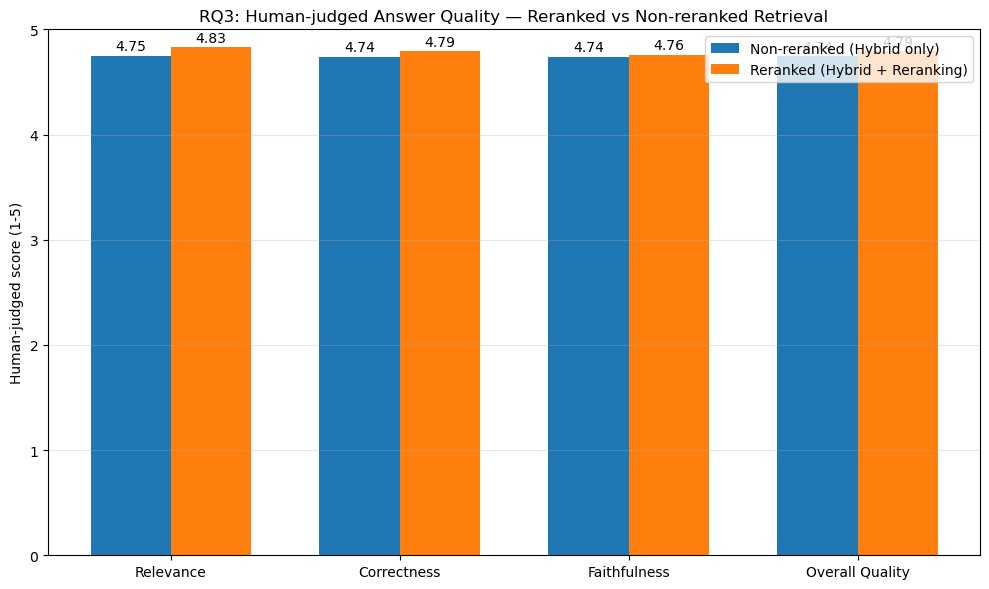

In [21]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Relevance", "Correctness", "Faithfulness", "Overall Quality"]
nonreranked_means = [
    rq3_df["relevance_1_5_nonreranked"].mean(),
    rq3_df["correctness_1_5_nonreranked"].mean(),
    rq3_df["faithfulness_1_5_nonreranked"].mean(),
    rq3_df["overall_quality_nonreranked"].mean()
]
reranked_means = [
    rq3_df["relevance_1_5_reranked"].mean(),
    rq3_df["correctness_1_5_reranked"].mean(),
    rq3_df["faithfulness_1_5_reranked"].mean(),
    rq3_df["overall_quality_reranked"].mean()
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, nonreranked_means, width, label="Non-reranked (Hybrid only)")
plt.bar(x + width/2, reranked_means, width, label="Reranked (Hybrid + Reranking)")

plt.xticks(x, labels)
plt.ylabel("Human-judged score (1-5)")
plt.ylim(0, 5)
plt.title("RQ3: Human-judged Answer Quality — Reranked vs Non-reranked Retrieval")
plt.legend()
plt.grid(axis="y", alpha=0.3)

for i, (v1, v2) in enumerate(zip(nonreranked_means, reranked_means)):
    plt.text(i - width/2, v1 + 0.05, f"{v1:.2f}", ha="center")
    plt.text(i + width/2, v2 + 0.05, f"{v2:.2f}", ha="center")

plt.tight_layout()
plt.savefig("RQ3_quality_comparison.png", dpi=150)
plt.show()

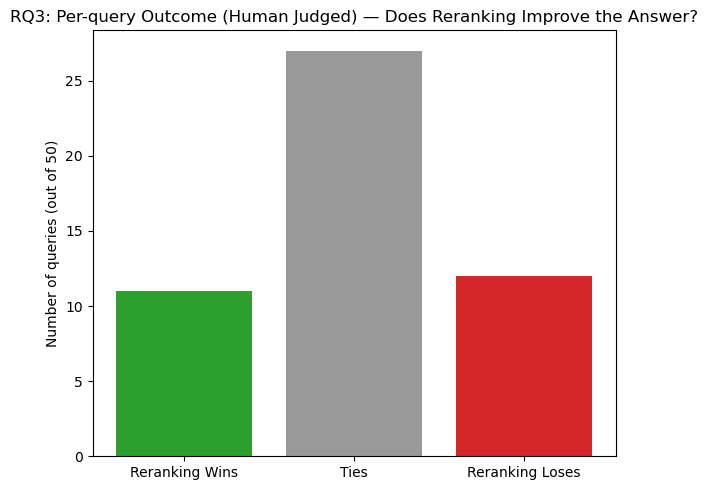

In [22]:
overall_row = next(r for r in rq3_summary if r["metric"] == "Overall Quality")

plt.figure(figsize=(6, 5))
plt.bar(
    ["Reranking Wins", "Ties", "Reranking Loses"],
    [overall_row["wins"], overall_row["ties"], overall_row["losses"]],
    color=["#2ca02c", "#999999", "#d62728"]
)
plt.ylabel("Number of queries (out of 50)")
plt.title("RQ3: Per-query Outcome (Human Judged) — Does Reranking Improve the Answer?")
plt.tight_layout()
plt.savefig("RQ3_win_tie_loss.png", dpi=150)
plt.show()

## RQ3 Step 9 — Conclusion

Read the `RQ3_final_results.csv` table above: if the **mean Overall Quality is higher for the reranked condition** and the **Wilcoxon p-value < 0.05**, the human evaluators found reranking produces a statistically significant improvement in generated-answer quality, not just in retrieval metrics. If the means are close and p ≥ 0.05, the human evaluation does not support a significant generation-quality improvement from reranking for this dataset/query set — worth noting since RQ1/RQ2 already showed Hybrid alone has Recall@10 = 0.98, almost identical to Hybrid + Reranking (0.98), so the gold chunk is already present in context for both conditions most of the time; RQ3 isolates whether reranking's effect on *ordering* (better MRR/NDCG) still helps once that context reaches a human reader of the generated answer.